# Week 3 Assignment: Linear Regression & Logistic Regression
**AI and Machine Learning Track**
## Instructions
1. Work through the notebook **from top to bottom**. Run every cell in order.
2. Replace each `# YOUR CODE HERE` cell with your own code. Read the **hint** under it if you get stuck.
3. For the **written answers**, double-click the answer box and type 2 to 4 sentences **in your own words**.
4. Before submitting, click **Kernel > Restart & Run All** (or *Runtime > Restart and run all* in Colab) to confirm your whole notebook runs without errors.
5. Save the notebook with the name `Week3_Assignment_YourName.ipynb` and submit it.


In [1]:
# Run this cell first. You may add more imports if you need them.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score, recall_score, f1_score)

---
# PART A: Linear Regression 
## Scenario
A shop in Abuja sells **used laptops**. The owner wants a model that suggests a fair selling price from the laptop's **RAM**, **storage** and **age**. You have records of **250 past sales**.

| Column | Meaning |
|---|---|
| `ram_gb` | RAM in gigabytes |
| `storage_gb` | Storage in gigabytes |
| `age_years` | Age of the laptop in years |
| `price_thousand` | Selling price in thousands of naira (**the label we want to predict**) |

In [2]:
# Run this cell to create the dataset. Do not change it.
rng = np.random.default_rng(2024)
n = 250

laptops = pd.DataFrame({
    "ram_gb":     rng.choice([4, 8, 16, 32], n, p=[0.2, 0.4, 0.3, 0.1]),
    "storage_gb": rng.choice([128, 256, 512, 1024], n, p=[0.2, 0.35, 0.3, 0.15]),
    "age_years":  rng.integers(0, 7, n),
})
laptops["price_thousand"] = (
    150 + 9 * laptops["ram_gb"] + 0.12 * laptops["storage_gb"]
    - 18 * laptops["age_years"] + rng.normal(0, 25, n)
).round(1)

laptops.head()

,ram_gb,storage_gb,age_years,price_thousand
0,16,1024,6,331.0
1,8,128,2,201.4
2,8,128,1,194.8
3,16,256,6,253.0
4,32,512,1,515.5


### A1. Explore the data

Using code, show: (a) the number of rows and columns, (b) the summary statistics, (c) whether there are missing values, and (d) the **correlation of every column with `price_thousand`**.

Then draw **one scatter plot** of `age_years` against `price_thousand` with axis labels and a title.

(250, 4)
           ram_gb   storage_gb   age_years  price_thousand
count  250.000000   250.000000  250.000000      250.000000
mean    11.296000   420.864000    3.220000      243.942400
std      7.739767   294.182451    1.986804       90.765017
min      4.000000   128.000000    0.000000       54.800000
25%      8.000000   256.000000    1.000000      177.650000
50%      8.000000   256.000000    3.000000      231.100000
75%     16.000000   512.000000    5.000000      284.900000
max     32.000000  1024.000000    6.000000      515.500000
                  ram_gb  storage_gb  age_years  price_thousand
ram_gb          1.000000    0.062919  -0.027496        0.808453
storage_gb      0.062919    1.000000   0.097766        0.404458
age_years      -0.027496    0.097766   1.000000       -0.355518
price_thousand  0.808453    0.404458  -0.355518        1.000000


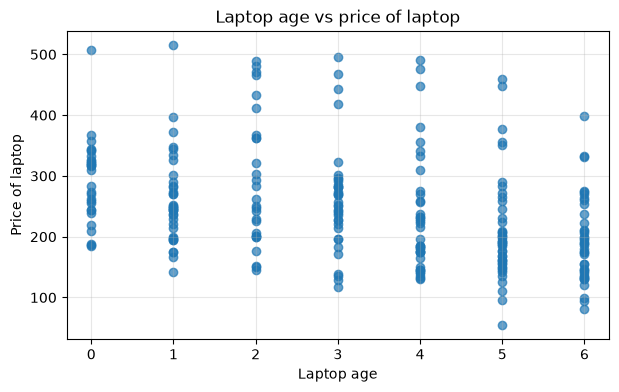

In [3]:
# YOUR CODE HERE
# Hint: `.shape`, `.describe()`, `.isnull().sum()`, `.corr()`, `plt.scatter(...)`.
print(laptops.shape)
print(laptops.describe())
laptops.isnull().sum()
print(laptops.corr())


plt.figure(figsize=(7,4))
plt.scatter(laptops["age_years"], laptops["price_thousand"], alpha=0.7)
plt.xlabel("Laptop age")
plt.ylabel("Price of laptop")
plt.title("Laptop age vs price of laptop")
plt.grid(alpha=0.3)
plt.show()

### A2. Prepare the data  
Create `X` (the three feature columns) and `y` (the label). Split into **80% training and 20% testing** using `random_state=42`. Print the number of rows in each set.

In [4]:
# YOUR CODE HERE
# Hint: `laptops[[...]]`, `train_test_split(X, y, test_size=..., random_state=...)`.
X = laptops[["age_years", "ram_gb", "storage_gb"]]
Y = laptops["price_thousand"]
print("X shape", X.shape)
print("Y shape", Y.shape)

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)


X shape (250, 3)
Y shape (250,)


In [5]:
X_train.columns

Index(['age_years', 'ram_gb', 'storage_gb'], dtype='str')

### A3. Train the model 

Train a **Linear Regression** model on the training data. Print the **intercept** and show the **coefficients in a table** (one row per feature).

In [6]:
# YOUR CODE HERE
# Hint: `LinearRegression()`, `.fit()`, `.intercept_`, `.coef_`, `pd.DataFrame(...)`.
model = LinearRegression()
model.fit(X_train, Y_train)

print("Intercept: ", round(model.intercept_, 2))
print("Coefficient_age: ", round(model.coef_[0], 2))
print("Coefficient_ram: ", round(model.coef_[1], 2))
print("Coefficient_storage: ", round(model.coef_[2], 2))

Y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Age": X_test["age_years"].values,
    "Actual_price": Y_test.values,
    "Predicted_price": Y_pred.round(1),
})
results["Difference"] = (results["Actual_price"] - results["Predicted_price"]).round(1)
results.head(5)

Intercept:  145.23
Coefficient_age:  -16.16
Coefficient_ram:  8.82
Coefficient_storage:  0.12


,Age,Actual_price,Predicted_price,Difference
0,1,196.5,196.0,0.5
1,4,140.4,147.5,-7.1
2,6,131.2,150.5,-19.3
3,1,237.4,231.3,6.1
4,5,207.5,221.4,-13.9


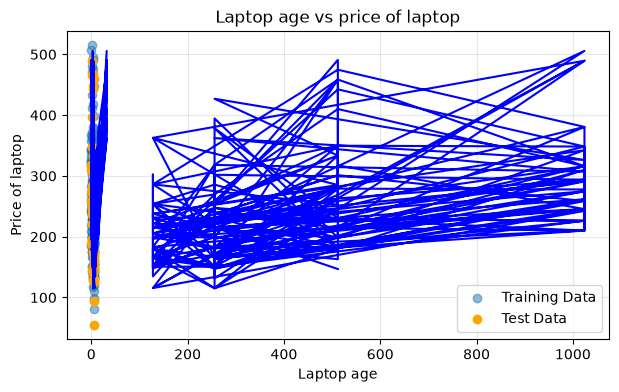

In [7]:
plt.figure(figsize=(7, 4))
plt.scatter(X_train["age_years"], Y_train, alpha=0.5, label= "Training Data")
plt.scatter(X_test["age_years"], Y_test, color="orange", label= "Test Data")

plt.plot(X_train, model.predict(X_train), color="blue")
plt.xlabel("Laptop age")
plt.ylabel("Price of laptop")
plt.title("Laptop age vs price of laptop")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### A4. Interpret the coefficients 

In your own words, explain what the coefficient of `age_years` means for the shop owner. Is it positive or negative, and does that make sense? Then say what the coefficient of `ram_gb` tells you.

**Your answer:**

*(double-click here and type your answer)*

For every increase in the age_years of the laptop the price drops by 16,160 and the higher the ram_gb the higher the price

### A5. Make a prediction 

Use your model to predict the price of a laptop with **16 GB RAM, 512 GB storage and 2 years old**. Print the answer in a sentence, for example: *"The predicted price is about N___ thousand."*

In [8]:
# YOUR CODE HERE
# Hint: Put the new laptop in a DataFrame with the **same column names** as `X`, then use `model.predict(...)`.
new_laptop = pd.DataFrame({"age_years": [1], "ram_gb": [64], "storage_gb": [512]})
predicted = model.predict(new_laptop)
print(f"A laptop that is 1 years old and has a ram of 64gb and 512gb storage is expected to cost {predicted[0]:.1f}k")

A laptop that is 1 years old and has a ram of 64gb and 512gb storage is expected to cost 757.1k


### A6. Evaluate the model 

Predict on the **test set** and calculate **MAE, RMSE and R²**. Print each with a short label.

Then draw an **Actual vs Predicted** scatter plot with a red dashed line showing perfect prediction.

In [9]:
# YOUR CODE HERE
# Hint: `model.predict(X_test)`, `mean_absolute_error`, `mean_squared_error` (then `np.sqrt`), `r2_score`.
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)

print(f"MAE : {mae:.2f} -> on average, the prediction is off by about N{mae:.1f} thousand")
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² : {r2:.3f} -> the model explains about {r2*100:.0f}% of the variation in prices " )

MAE : 21.28 -> on average, the prediction is off by about N21.3 thousand
MSE : 788.33
RMSE: 28.08
R² : 0.929 -> the model explains about 93% of the variation in prices 


### A7. Is the model good?  

Use your MAE and R² values to explain, in plain language, how good the model is. Would you trust it to price laptops in the shop? Give one idea for improving it.

**Your answer:**

*(double-click here and type your answer)*

---
# PART B: Logistic Regression 
## Scenario
A microfinance company in Nigeria gives small loans. For each past loan they know whether the customer **repaid (1)** or **did not repay (0)**. They want a model to help decide whether to approve **new** applicants. You have records of **400 past loans**.

| Column | Meaning |
|---|---|
| `monthly_income_k` | Customer's monthly income (N thousand) |
| `loan_amount_k` | Loan amount requested (N thousand) |
| `years_employed` | Years in current job or business |
| `previous_defaults` | Number of earlier loans not repaid |
| `repaid` | 1 = repaid, 0 = did not repay (**the label**) |

In [10]:
# Run this cell to create the dataset. Do not change it.
rng = np.random.default_rng(99)
m = 400

loans = pd.DataFrame({
    "monthly_income_k":  rng.normal(120, 40, m).clip(30).round(0),
    "loan_amount_k":     rng.uniform(20, 500, m).round(0),
    "years_employed":    rng.uniform(0, 15, m).round(1),
    "previous_defaults": np.minimum(rng.poisson(0.6, m), 3),
})
z = (-1.0 + 0.025 * loans["monthly_income_k"] - 0.008 * loans["loan_amount_k"]
     + 0.12 * loans["years_employed"] - 1.2 * loans["previous_defaults"])
prob = 1 / (1 + np.exp(-z))
loans["repaid"] = (rng.random(m) < prob).astype(int)

loans.head()

,monthly_income_k,loan_amount_k,years_employed,previous_defaults,repaid
0,123.0,407.0,14.0,2,1
1,101.0,407.0,2.1,1,0
2,122.0,339.0,12.9,0,1
3,147.0,408.0,8.6,0,1
4,50.0,202.0,2.3,1,0


### B1. Explore the data

Show (a) how many loans were repaid and not repaid (counts **and** percentages), and (b) the **average of each feature for repaid vs not repaid** loans.

Then, in one sentence in a comment or print statement, say which feature seems to differ the most between the two groups.

In [11]:
# YOUR CODE HERE
# Hint: `.value_counts()`, `.value_counts(normalize=True)`, `.groupby('repaid').mean()`.
loans.value_counts()
loans.value_counts(normalize=True)
loans.groupby('repaid').mean()

# The feature that differs is the loan amount cause the customer with the high loan amount had 0.8 previous default while the customer who had less loan amount had 0.4 default loan so therefore the higher the loan amount the more chance they'll default on it.

,monthly_income_k,loan_amount_k,years_employed,previous_defaults
repaid,,,,
0,107.861386,329.955446,7.079208,0.836634
1,131.762626,217.858586,7.582828,0.479798


### B2. Prepare and train 

Create `X` (all columns except `repaid`) and `y`. Split into 80% training and 20% testing with `random_state=42` and **`stratify=y`**.

Build a **pipeline** that scales the features with `StandardScaler` and then trains a `LogisticRegression`. Fit it on the training data.

In [12]:
# YOUR CODE HERE
# Hint: `make_pipeline(StandardScaler(), LogisticRegression())`, then `.fit(X_train, y_train)`.
x = loans.drop(columns="repaid")
y = loans["repaid"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)
print("Train: ", x_train.shape, "Test: ", x_test.shape)

Train:  (320, 4) Test:  (80, 4)


### B3. Accuracy and a new applicant

(a) Print the model's **accuracy on the test set**.

(b) A new applicant earns **N90 thousand** a month, wants a loan of **N250 thousand**, has been employed for **3 years** and has **1 previous default**. Print the **predicted class** and the **probability of repaying**.

In [13]:
# YOUR CODE HERE
# Hint: `accuracy_score`, `log_model.predict(...)`, `log_model.predict_proba(...)`. The probability of class 1 is the **second** number.

loan_model = make_pipeline(StandardScaler(), LogisticRegression())
loan_model.fit(x_train,y_train)

loan_pred = loan_model.predict(x_test)
print("Logistic Regression accuracy: ", round(accuracy_score(y_test, loan_pred), 3))

Logistic Regression accuracy:  0.725


In [14]:
new_customer = pd.DataFrame({"monthly_income_k": [60], "loan_amount_k": [300], "years_employed": [3.4], "previous_defaults": [1]})

print("predicted class:", loan_model.predict(new_customer)[0], "(1 = repaid, 0 =  defaulted)")
proba = loan_model.predict_proba(new_customer)[0]
print(f"probability of defaulting(0): {proba[0]:.2f}")
print(f"probability of repayment(1): {proba[1]:.2f}")


predicted class: 0 (1 = repaid, 0 =  defaulted)
probability of defaulting(0): 0.90
probability of repayment(1): 0.10


### B4. Evaluate with a confusion matrix 

Show the **confusion matrix** (as a plot or printed table) and a **classification report** for the test set.

[[29 11]
 [11 29]]


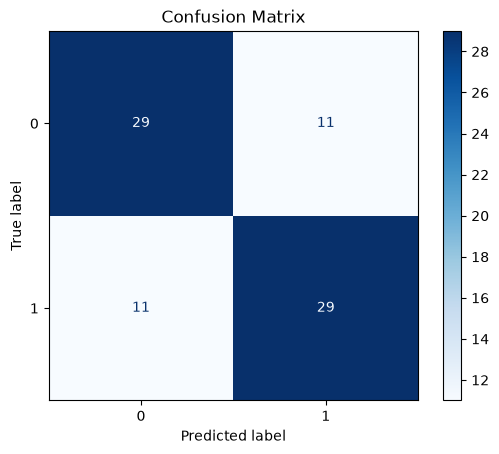

In [15]:
# YOUR CODE HERE
# Hint: `confusion_matrix`, `ConfusionMatrixDisplay`, `classification_report`.

cm = confusion_matrix(y_test, loan_pred)
print(cm)

ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()


In [16]:
tn, fp,fn,tp = cm.ravel()
print(f"True Negatives: {tn} (model correctly predicted default)")
print(f"False Positive: {fp} (model prdicted 1(repaid) but it was default )")
print(f"False Negative: {fn} (model predicted (0)default but it was repaid)")
print(f"True Positive: {tp} (model correctly predicted repayment)")

True Negatives: 29 (model correctly predicted default)
False Positive: 11 (model prdicted 1(repaid) but it was default )
False Negative: 11 (model predicted (0)default but it was repaid)
True Positive: 29 (model correctly predicted repayment)


In [17]:
print(f"Accuracy : {accuracy_score(y_test, loan_pred):.3f}")
print(f"Precision: {precision_score(y_test, loan_pred):.3f}")
print(f"Recall   : {recall_score(y_test, loan_pred):.3f}")
print(f"F1-score : {f1_score(y_test, loan_pred):.3f}")

Accuracy : 0.725
Precision: 0.725
Recall   : 0.725
F1-score : 0.725


In [18]:
print(classification_report(y_test, loan_pred))

              precision    recall  f1-score   support

           0       0.72      0.72      0.72        40
           1       0.72      0.72      0.72        40

    accuracy                           0.72        80
   macro avg       0.72      0.72      0.72        80
weighted avg       0.72      0.72      0.72        80



### B5. Which mistake is worse? 

In this loan problem, **1 = repaid** is the "positive" class.

Explain in your own words what a **false positive** and a **false negative** mean here. Which one costs the company more, and which metric (precision or recall for the "Repaid" class) would you watch most closely?

**Your answer:**

*(double-click here and type your answer)*

A False Positive can be said to be when a model predicted "yes"(positive) but it was "wrong"(false) and a False Negative is when a model predicted "No"(negative) but it was "wrong" (false).
In the case of the loan model it predicted that 11 people would repay when they actually defaulted and this incurs losses on the bank and for the false negative it predicted that 11 people would default when they actually could have repaid and this leads to the bank losing potential customers.

I'll watch out for the precision cause that tells us if when the model predicted positive was it really correct and in this case the model was 72.5% precise and also the recall is 72.5% as it was able to find 22 people of which 11 could have repaid but defaulted instead and 11 could have defaulted but repaid if we had depended on the accuracy in which it detected 58 people 29 who repaid an 29 who defaulted we wouls have missed out on 22 people leading to a potential loss or gain on the bank

### B6. Compare with a Decision Tree 

Train a `DecisionTreeClassifier(max_depth=3, random_state=42)` on the same training data and print its **test accuracy**. Then print the two accuracies side by side. Which model did better?

In [19]:
# YOUR CODE HERE
# Hint: Trees do not need scaling. Use `.fit()`, `.predict()` and `accuracy_score`.
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(x_train, y_train)

tree_pred = tree_model.predict(x_test)
print("Decision Tree Accuracy:", round(accuracy_score(y_test, tree_pred), 3))

print("Logistic Regression accuracy: ", round(accuracy_score(y_test, loan_pred), 3))

print("The Logisitic regression model did better that the decision tree model ")

Decision Tree Accuracy: 0.613
Logistic Regression accuracy:  0.725
The Logisitic regression model did better that the decision tree model 


### B7. Challenge: change the decision threshold 

By default the model approves anyone with a repayment probability **above 0.5**. The company wants to be **stricter** and only approve applicants with a probability **above 0.7**.

Use `predict_proba` to apply this new threshold on the test set, then print the **precision and recall** for the "Repaid" class **before and after**. What changed?

In [20]:
# YOUR CODE HERE
# Hint: `probs = log_model.predict_proba(X_test)[:, 1]`, then `new_pred = (probs > 0.7).astype(int)`.
proba = loan_model.predict_proba(x_test)[:, 1]
new_pred = (proba > 0.7).astype(int)

print(f"probability of defaulting(0): {proba[0]:.2f}")
print(f"probability of repayment(1): {proba[1]:.2f}")

probability of defaulting(0): 0.77
probability of repayment(1): 0.68


In [21]:
print(f"Precision: {precision_score(y_test, new_pred):.3f}")
print(f"Recall   : {recall_score(y_test, new_pred):.3f}")

Precision: 0.818
Recall   : 0.450


I noticed that the threshold for defaulting on the loan has dropped down to 77% and the threshold for repayment is 68% and also the precison has increased to 82% and the recall has increased to 45%. 
Compared to the old model this decreases the chances of a bank having losses and increases the threshold of repayment 

---
# PART C: Reflection
Answer in your own words, in 2 to 4 sentences each.

### C1. Linear vs Logistic

What is the main difference between Linear Regression and Logistic Regression? Give one real-life example for each.

**Your answer:**

*(double-click here and type your answer)*

Logistic Regression is a classification algorithm that calculates probability 0 and 1 while linear regression predicts continuous variables

### C2. Why split the data? 

Why do we split our data into a training set and a test set? What could go wrong if we tested the model on the same data it learned from?

**Your answer:**

*(double-click here and type your answer)*

Because if a model is tested with the training test it would give perfect answers cause it has crammed every thing and prevents you from catching any errors


### C3. Why scale for logistic regression? 

In Part B we used `StandardScaler` before logistic regression. Why is scaling useful when features such as `monthly_income_k` (about 120) and `previous_defaults` (0 to 3) have very different ranges?

**Your answer:**

*(double-click here and type your answer)*

it reduces the mean to 0 and standard deviation to 1 and it removes bias

---
## Before you submit: checklist
- [ ] I ran **Restart & Run All** and there are no errors
- [ ] Every `# YOUR CODE HERE` cell has my own code
- [ ] I answered all the written questions in my own words
- [ ] My plots have titles and axis labels
- [ ] I saved the file as `Week3_Assignment_YourName.ipynb`

**Good luck!**